# Review Radar - Collect, Clean, Load into PostgreSQL

## Step 0 - Install libraries
`google-play-scraper` fetches public reviews, `pandas` cleans them, `sqlalchemy` + `psycopg2-binary` talk to Postgres, `matplotlib` draws charts.

In [ ]:
%pip install -q google-play-scraper pandas sqlalchemy psycopg2-binary matplotlib

## Step 1 - Configuration


In [2]:
from datetime import datetime, timedelta
import time
import pandas as pd

APPS = {
    "Blinkit":   "com.grofers.customerapp",
    "Zepto":     "com.zeptoconsumerapp",
    "BigBasket": "com.bigbasket.mobileapp",
}
DAYS_BACK = 90
MAX_PER_APP = 25000
TEST_MODE = False

CUTOFF = datetime.now() - timedelta(days=DAYS_BACK)
CAP = 500 if TEST_MODE else MAX_PER_APP

## Step 2 - Scrape reviews


In [3]:
from google_play_scraper import reviews, Sort

def scrape_app(app_name, app_id, cutoff, cap):
    rows, token = [], None
    while len(rows) < cap:
        batch, token = reviews(app_id, lang="en", country="in", sort=Sort.NEWEST,
                               count=200, continuation_token=token)
        if not batch:
            break
        rows.extend(batch)
        if min(r["at"] for r in batch) < cutoff:
            break
        time.sleep(1)
    df = pd.DataFrame(rows).drop(columns=["userName", "userImage"], errors="ignore")
    df["app_name"] = app_name
    print(f"{app_name}: {len(df)} reviews, oldest {df['at'].min():%Y-%m-%d}")
    return df

raw = pd.concat([scrape_app(n, i, CUTOFF, CAP) for n, i in APPS.items()], ignore_index=True)
raw.to_csv("reviews_raw.csv", index=False)   # keep the untouched copy: never overwrite raw data
raw.head(3)

Blinkit: 25000 reviews, oldest 2026-09-12
Zepto: 21000 reviews, oldest 2026-07-03
BigBasket: 22200 reviews, oldest 2026-07-04


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app_name
0,3ef5ab9c-ca81-45ae-930f-a9c16b194866,blinkit is good,1,0,18.29.0,2026-10-01 14:58:40,"Hi Sirrri, thank you for the praise. We will l...",2026-10-01 18:33:33,18.29.0,Blinkit
1,9ecbbbb2-d4a0-4fa5-9272-0a7d23d32238,very bad customer service. for an damaged shoe...,1,0,18.29.0,2026-10-01 14:58:33,"Hi there, extremely sorry for the kind of expe...",2026-10-01 15:09:23,18.29.0,Blinkit
2,b5969e35-cd14-4fd4-ad90-9bf49172fc4a,good,5,0,18.33.0,2026-10-01 14:57:58,It is delightful to hear such positive words a...,2026-10-01 15:07:13,18.33.0,Blinkit


## Step 3 - Clean the data
**Why each rule exists:**
- *Rename columns* to clear snake_case names (easier SQL later).
- *App version*: newer reviews carry `appVersion`, older ones `reviewCreatedVersion`; we take whichever exists. Many rows will still be empty - normal, and we will state that limitation in the README.
- *Drop duplicates* by review id, and drop rows with no text or rating, because they can't be analysed.
- *Collapse whitespace* so the same text is not stored in 5 different shapes.
- *week_start* (Monday of each week) is the key for all weekly trend analysis later.
- *is_taggable* = at least 4 words. Reviews like "good" or "nice app" carry no topic, so we won't spend AI calls on them. They still count in ratings.

In [4]:
def clean_reviews(raw):
    df = raw.rename(columns={"reviewId": "review_id", "content": "review_text", "score": "rating",
                             "thumbsUpCount": "thumbs_up", "at": "review_date"}).copy()
    ver_cols = [c for c in ["appVersion", "reviewCreatedVersion"] if c in df.columns]
    df["app_version"] = df[ver_cols].bfill(axis=1).iloc[:, 0] if ver_cols else None
    df["has_dev_reply"] = df["replyContent"].notna() if "replyContent" in df.columns else False

    df = df.drop_duplicates("review_id")
    df = df.dropna(subset=["review_text", "rating"])
    df["review_text"] = df["review_text"].str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[df["review_text"] != ""]

    df["review_date"] = pd.to_datetime(df["review_date"])
    df["week_start"] = (df["review_date"] - pd.to_timedelta(df["review_date"].dt.weekday, unit="D")).dt.normalize()
    df["word_count"] = df["review_text"].str.split().str.len()
    df["is_taggable"] = df["word_count"] >= 4
    df["rating"] = df["rating"].astype(int)
    assert df["rating"].between(1, 5).all(), "ratings must be 1-5"

    cols = ["review_id", "app_name", "rating", "review_text", "review_date", "week_start",
            "thumbs_up", "app_version", "has_dev_reply", "word_count", "is_taggable"]
    return df[cols].reset_index(drop=True)

clean = clean_reviews(raw)
print(f"{len(raw)} raw rows -> {len(clean)} clean rows")

68200 raw rows -> 68200 clean rows


In [5]:
common_start = clean.groupby("app_name")["review_date"].min().max()
print("Common window starts:", common_start.date())
print(clean[clean["review_date"] >= common_start].groupby("app_name").size())

Common window starts: 2026-09-12
app_name
BigBasket     3170
Blinkit      25000
Zepto         3885
dtype: int64


## Step 4 - Profile the data

In [6]:
print(clean.isna().mean().round(3))
clean.groupby("app_name").agg(
    reviews=("review_id", "count"),
    avg_rating=("rating", "mean"),
    first_review=("review_date", "min"),
    last_review=("review_date", "max"),
    share_with_version=("app_version", lambda s: s.notna().mean()),
    share_taggable=("is_taggable", "mean"),
).round(2)

review_id        0.000
app_name         0.000
rating           0.000
review_text      0.000
review_date      0.000
week_start       0.000
thumbs_up        0.000
app_version      0.113
has_dev_reply    0.000
word_count       0.000
is_taggable      0.000
dtype: float64


,reviews,avg_rating,first_review,last_review,share_with_version,share_taggable
app_name,,,,,,
BigBasket,22200,4.16,2026-07-04 11:29:01,2026-10-01 15:02:27,0.92,0.39
Blinkit,25000,4.10,2026-09-12 23:03:41,2026-10-01 14:58:40,0.87,0.38
Zepto,21000,3.31,2026-07-03 17:14:47,2026-10-01 14:53:04,0.88,0.54


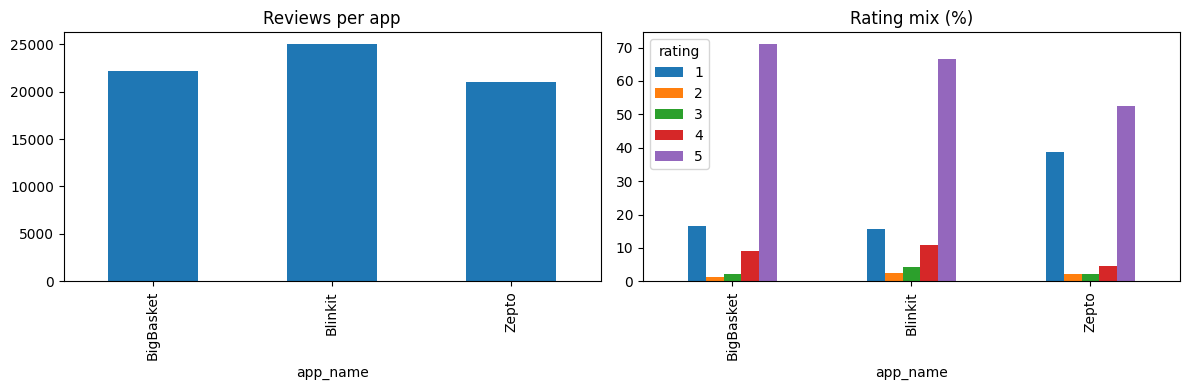

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
clean.groupby("app_name").size().plot.bar(ax=ax[0], title="Reviews per app")
pd.crosstab(clean["app_name"], clean["rating"], normalize="index").mul(100).round(1).plot.bar(ax=ax[1], title="Rating mix (%)")
plt.tight_layout(); plt.show()
clean.to_csv("reviews_clean.csv", index=False)

## Step 5 - Create the database in pgAdmin 4


In [11]:
import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

pw = getpass.getpass("Postgres password: ")      # typed at runtime, never saved in the file
engine = create_engine(URL.create("postgresql+psycopg2", username="postgres", password=pw,
                                  host="localhost", port=5432, database="review_radar"))
with engine.connect() as conn:
    print(conn.execute(text("SELECT version()")).scalar())

Postgres password:  ········


PostgreSQL 18.4 on x86_64-windows, compiled by msvc-19.44.35227, 64-bit


## Step 6 - Create the table and load the data


In [12]:
DDL = """
DROP TABLE IF EXISTS reviews;
CREATE TABLE reviews (
    review_id     TEXT PRIMARY KEY,
    app_name      TEXT NOT NULL,
    rating        SMALLINT NOT NULL CHECK (rating BETWEEN 1 AND 5),
    review_text   TEXT NOT NULL,
    review_date   TIMESTAMP NOT NULL,
    week_start    DATE NOT NULL,
    thumbs_up     INTEGER,
    app_version   TEXT,
    has_dev_reply BOOLEAN,
    word_count    INTEGER,
    is_taggable   BOOLEAN
);
CREATE INDEX idx_reviews_app_week ON reviews (app_name, week_start);
"""
with engine.begin() as conn:
    conn.execute(text(DDL))

clean.to_sql("reviews", engine, if_exists="append", index=False, method="multi", chunksize=5000)
print(pd.read_sql("SELECT app_name, COUNT(*) AS reviews FROM reviews GROUP BY app_name", engine))

    app_name  reviews
0      Zepto    21000
1  BigBasket    22200
2    Blinkit    25000
